# Get To Know A Dataset: ML4HP-US — Hurricane Helene (September 2024)

**AWS Open Data Sponsorship Program — draft introductory notebook**  
**Dataset:** Machine Learning for High-Resolution Precipitation – United States (ML4HP-US)  
**Maintainer:** Hydroclimate Research Group, Auburn University  
**Documentation:** https://github.com/Hydroclimate-AI/ML4HP-US

This beginner-friendly tutorial explains how to locate, inspect, subset, visualize, and aggregate **hourly 4-km ML4HP-US precipitation** during **Hurricane Helene in September 2024**. It is written for the existing Delta NetCDF archive and will be adapted to public S3 access once the AWS bucket is configured.

> **Data availability:** The ML4HP-US public archive is not yet released. All resulting figures must be generated from your data; no precipitation results or comparisons are assumed in advance.  
> **Event window:** September 26–29, 2024 (UTC-labeled hourly intervals). This is an illustrative analysis window, not an attribution of rainfall solely to the tropical cyclone.

## 1. About ML4HP-US

ML4HP-US spans **2002–2025**, covering the contiguous United States at approximately **4-km** and **hourly** resolution. It combines radar, satellite, reanalysis, and terrain inputs using the XTPrecip deep-learning framework, calibrated with NOAA COOP rain-gauge observations. It is distributed as **monthly NetCDF files** with one-dimensional geographic `lat` and `lon` coordinates.

| Variable | Meaning | Units |
|---|---|---|
| `precip_raw` | Blended model precipitation estimate | mm h⁻¹ |
| `precip_scaled` | Intensity-scaled blended estimate (recommended primary field) | mm h⁻¹ |

**Important conventions:** A timestamp represents the **start** of a one-hour precipitation accumulation interval. A value of 12 mm h⁻¹ over that one-hour interval contributes **12 mm** to the total. `NaN` means missing, **not zero precipitation**. See the [README](https://github.com/Hydroclimate-AI/ML4HP-US) for production and release caveats.

**Requirements:** Python, `numpy`, `xarray`, `netCDF4`, `matplotlib`, and optionally `pandas`. No Cartopy dependency is required for these introductory plots.

## 2. Configure local data access

On Delta, the monthly archive is expected under `/work/nvme/bhko/fangwang/generate_data_regions/blended_generation/`. **Hurricane Helene occurred in September 2024**, so this notebook uses the `2024` directory, **not** the `2025` directory previously used for the Texas-flood example. Change `DATA_ROOT` if your directory structure differs.

In [1]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

DATA_ROOT = Path('/work/nvme/bhko/fangwang/generate_data_regions/blended_generation')
DATA_FILE = DATA_ROOT / '2024' / 'blended_precip_2024_09.nc'
OUTPUT_DIR = Path.cwd() / 'helene_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_FILE.is_file():
    found = sorted((DATA_ROOT / '2024').glob('*.nc')) if (DATA_ROOT / '2024').exists() else []
    raise FileNotFoundError(
        f'Expected September 2024 file: {DATA_FILE}\n'
        f'Files found in 2024 directory (first 20): {[p.name for p in found[:20]]}\n'
        'Update DATA_FILE to your real September 2024 filename.'
    )
print('Input:', DATA_FILE)
print('Size (GB):', round(DATA_FILE.stat().st_size / 1e9, 2))

Input: /work/nvme/bhko/fangwang/generate_data_regions/blended_generation/2024/blended_precip_2024_09.nc
Size (GB): 2.12


## 3. Open the NetCDF file and examine its metadata

Opening a NetCDF file with xarray normally reads metadata first, without loading the entire monthly precipitation array into memory.

In [2]:
ds = xr.open_dataset(DATA_FILE, decode_times=True, mask_and_scale=True)
print(ds)
print('Variables:', list(ds.data_vars))
print('Dimensions:', dict(ds.sizes))
print('Coordinates:', list(ds.coords))
print('Global attributes:', ds.attrs)

required_dims = {'time', 'lat', 'lon'}
assert required_dims.issubset(ds.sizes), f'Missing required dimensions: {required_dims - set(ds.sizes)}'
assert 'precip_scaled' in ds.data_vars, 'Expected precip_scaled; inspect the actual variable names.'
assert np.ndim(ds['lat']) == 1 and np.ndim(ds['lon']) == 1, 'This notebook assumes 1D latitude/longitude.'

print('First time:', ds.time.values[0], 'Last time:', ds.time.values[-1])
for variable in ('precip_raw', 'precip_scaled'):
    if variable in ds:
        print(variable, ds[variable].attrs)

<xarray.Dataset> Size: 6GB
Dimensions:                (time: 720, lat: 676, lon: 1500)
Coordinates:
  * time                   (time) datetime64[ns] 6kB 2024-09-01 ... 2024-09-3...
  * lat                    (lat) float32 3kB 24.0 24.04 24.08 ... 50.96 51.0
  * lon                    (lon) float32 6kB -126.0 -126.0 ... -66.08 -66.04
Data variables:
    precip_raw             (time, lat, lon) float32 3GB ...
    precip_scaled          (time, lat, lon) float32 3GB ...
    blend_weight_sum       (lat, lon) float32 4MB ...
    final_generation_mask  (lat, lon) int8 1MB ...
Attributes:
    description:   Hourly precipitation blended from seven NCA regional XTPre...
    year:          2024
    month:         9
    regions:       northwest,southwest,northern_great_plains,southern_great_p...
    blend_method:  regional precipitation multiplied by regional blend weight...
Variables: ['precip_raw', 'precip_scaled', 'blend_weight_sum', 'final_generation_mask']
Dimensions: {'time': 720, 'lat': 676

## 4. Select a geographic region and storm period

For an introductory Hurricane Helene case study, select an **illustrative Southeast / southern Appalachian domain**: 29–38°N, 88–80°W. This is a rectangular geographic subset, **not** a storm footprint or watershed boundary. Modify the box to focus on a specific area of interest.

The event period below includes all hour-start timestamps from **2024-09-26 00:00** through **2024-09-29 23:00** (96 hours if every hour is present).

In [3]:
LAT_MIN, LAT_MAX = 29.0, 38.0
LON_MIN, LON_MAX = -88.0, -80.0
START, END = '2024-09-26T00:00:00', '2024-09-29T23:00:00'
VARIABLE = 'precip_scaled'  # recommended primary product

def ordered_slice(coord, low, high):
    vals = coord.values
    return slice(low, high) if vals[0] <= vals[-1] else slice(high, low)

# Some geographic files encode longitude from 0 to 360; convert selection bounds if needed.
lon = ds['lon']
if float(lon.min()) >= 0:
    lon_low, lon_high = LON_MIN % 360, LON_MAX % 360
else:
    lon_low, lon_high = LON_MIN, LON_MAX

rain = ds[VARIABLE].sel(
    time=slice(START, END),
    lat=ordered_slice(ds['lat'], LAT_MIN, LAT_MAX),
    lon=ordered_slice(ds['lon'], lon_low, lon_high)
)
if any(rain.sizes[d] == 0 for d in ('time', 'lat', 'lon')):
    raise ValueError('Empty selection. Inspect coordinate ranges and time values printed above.')

print(rain)
print('Selected hourly timestamps:', rain.sizes['time'])
print('Selected time coverage:', str(rain.time.values[0]), 'to', str(rain.time.values[-1]))
print('Expected 96 records for the configured 4-day period.')
if rain.sizes['time'] != 96:
    print('WARNING: the requested 4-day window does not contain 96 hourly records.')

<xarray.DataArray 'precip_scaled' (time: 96, lat: 226, lon: 201)> Size: 17MB
[4360896 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 768B 2024-09-26 ... 2024-09-29T23:00:00
  * lat      (lat) float32 904B 29.0 29.04 29.08 29.12 ... 37.92 37.96 38.0
  * lon      (lon) float32 804B -88.0 -87.96 -87.92 ... -80.08 -80.04 -80.0
Attributes:
    long_name:  seven-region blended power-corrected precipitation
    units:      mm h-1
Selected hourly timestamps: 96
Selected time coverage: 2024-09-26T00:00:00.000000000 to 2024-09-29T23:00:00.000000000
Expected 96 records for the configured 4-day period.


## 5. Inspect an hourly precipitation field

The figure below shows precipitation for a selected example timestamp; set `MAP_TIME` to another available UTC hour to explore changes. The longitude and latitude axes are geographic coordinates, not a projected distance-preserving map.

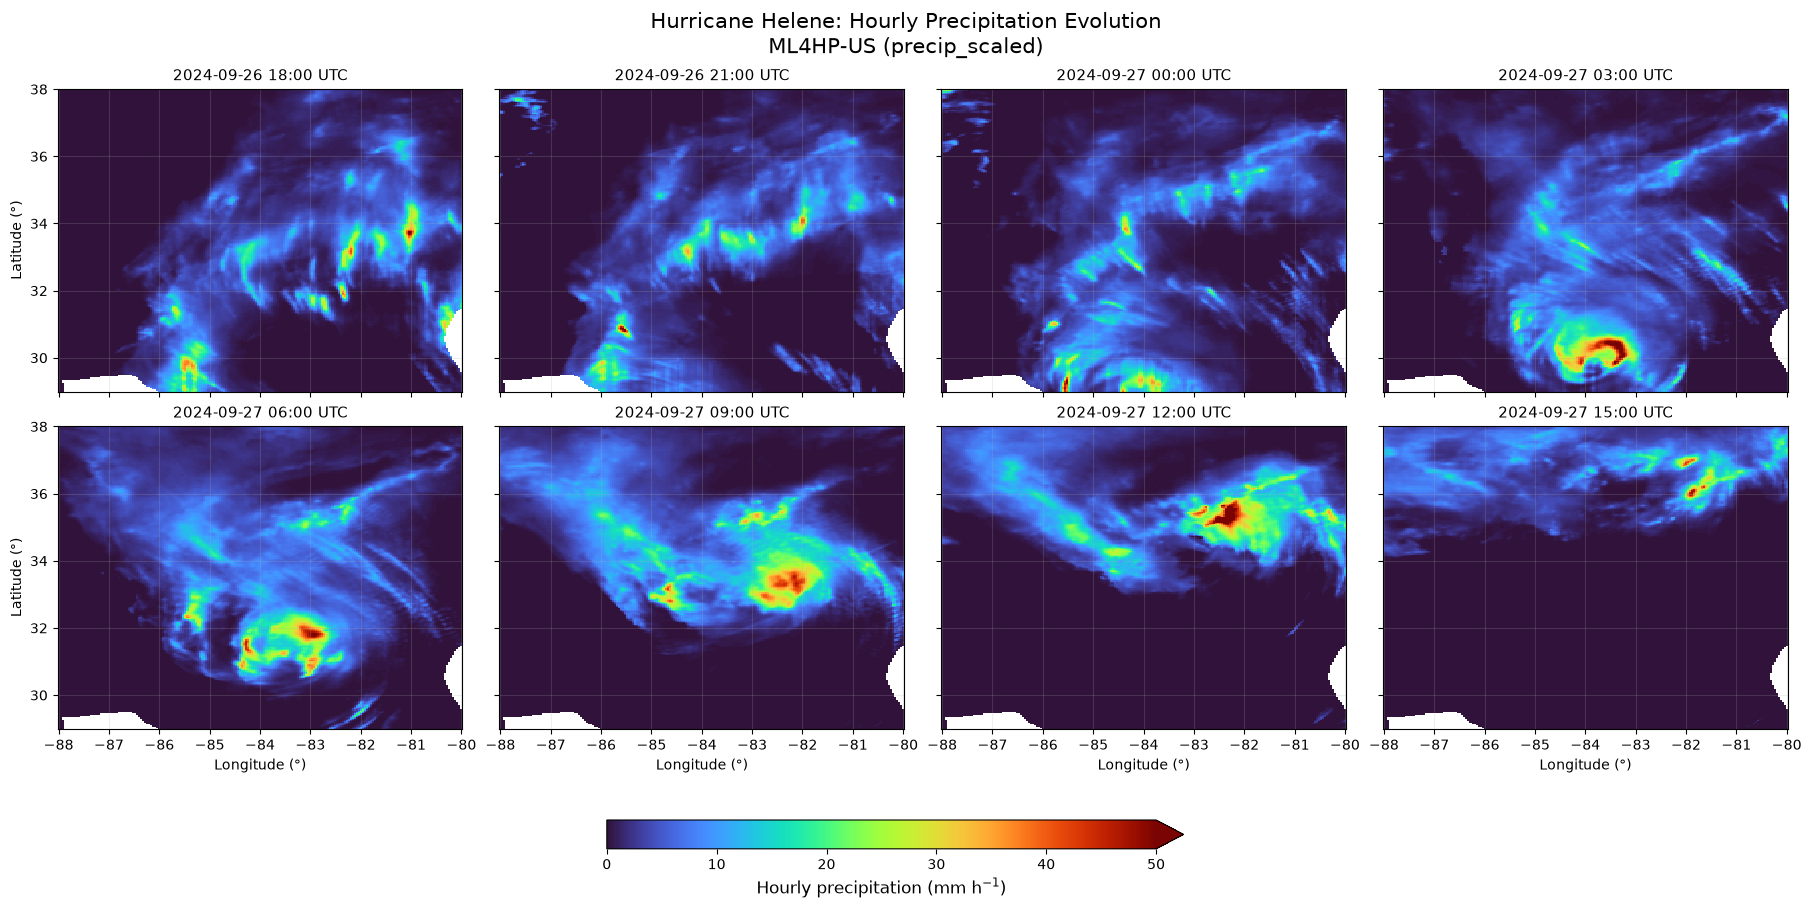

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Eight snapshots at 3-hour intervals
MAP_TIMES = pd.date_range(
    start="2024-09-26T18:00:00",
    periods=8,
    freq="3h"
)

# Extract all eight frames
frames = rain.sel(time=MAP_TIMES, method="nearest").load()

# Determine common color scale
VMIN = 0
VMAX = 50  # mm/h; adjust based on precipitation intensity

# Create 2 rows × 4 columns
fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 9),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for i, ax in enumerate(axes.flat):

    frame = frames.isel(time=i)

    mesh = ax.pcolormesh(
        frame.lon,
        frame.lat,
        frame,
        shading="auto",
        cmap="turbo",
        vmin=VMIN,
        vmax=VMAX
    )

    timestamp = pd.Timestamp(frame.time.values)

    ax.set_title(
        timestamp.strftime("%Y-%m-%d %H:%M UTC"),
        fontsize=11
    )

    ax.grid(alpha=0.2)

    if i // 4 == 1:
        ax.set_xlabel("Longitude (°)")

    if i % 4 == 0:
        ax.set_ylabel("Latitude (°)")

# Shared colorbar
cbar = fig.colorbar(
    mesh,
    ax=axes,
    orientation="horizontal",
    fraction=0.045,
    pad=0.07,
    extend="max"
)

cbar.set_label("Hourly precipitation (mm h$^{-1}$)", fontsize=12)

fig.suptitle(
    f"Hurricane Helene: Hourly Precipitation Evolution\n"
    f"ML4HP-US ({VARIABLE})",
    fontsize=15
)

fig.savefig(
    OUTPUT_DIR / "helene_hourly_evolution_8panels.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 6. Explore how precipitation changes with time

Here we summarize each hour with the *regional maximum* and the *unweighted regional grid-cell mean*. These are descriptive measures: the maximum is sensitive to individual extreme grid cells, while the mean is not area-weighted (a geographic-degree grid has varying physical cell area).

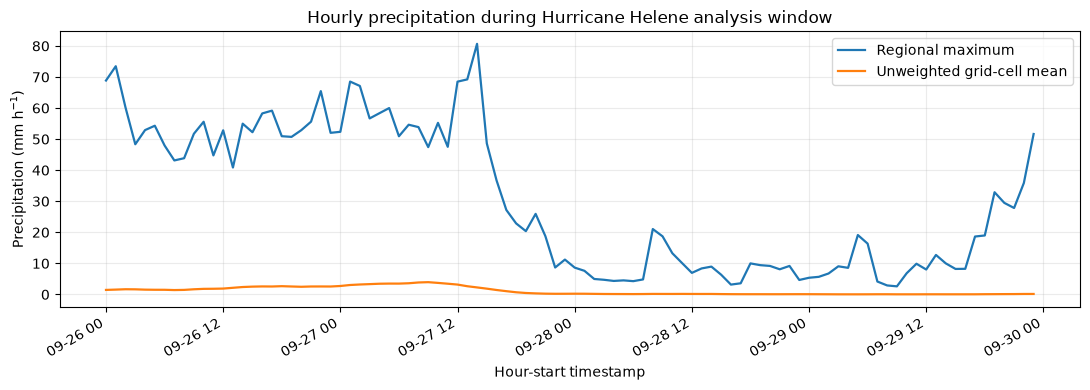

Hour with largest regional grid-cell precipitation: 2024-09-27T14:00:00.000000000
Regional maximum during that hour (mm/h): 80.67078399658203


In [5]:
# Compute only the selected subregion rather than the full CONUS archive.
hourly_max = rain.max(dim=('lat', 'lon'), skipna=True).load()
hourly_mean = rain.mean(dim=('lat', 'lon'), skipna=True).load()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hourly_max.time.values, hourly_max.values, label='Regional maximum', linewidth=1.6)
ax.plot(hourly_mean.time.values, hourly_mean.values, label='Unweighted grid-cell mean', linewidth=1.6)
ax.set(xlabel='Hour-start timestamp', ylabel='Precipitation (mm h$^{-1}$)',
       title='Hourly precipitation during Hurricane Helene analysis window')
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'helene_hourly_timeseries.png', dpi=180)
plt.show()

peak_idx = int(hourly_max.argmax(dim='time').item())
print('Hour with largest regional grid-cell precipitation:', str(hourly_max.time.values[peak_idx]))
print('Regional maximum during that hour (mm/h):', float(hourly_max.values[peak_idx]))

## 7. Calculate storm-window precipitation totals (mm)

Summing a rate in **mm h⁻¹** over 1-hour intervals yields a total in **mm**. A missing value (`NaN`) must **not** be counted as zero. This notebook masks any grid cell that is missing one or more of the expected hourly records during the period. It also checks for missing timestamps across the file, so no seemingly complete subset can be mistaken for a complete 96-hour event.

Expected hours: 96 | Available: 96
Missing hour-start timestamps: 0


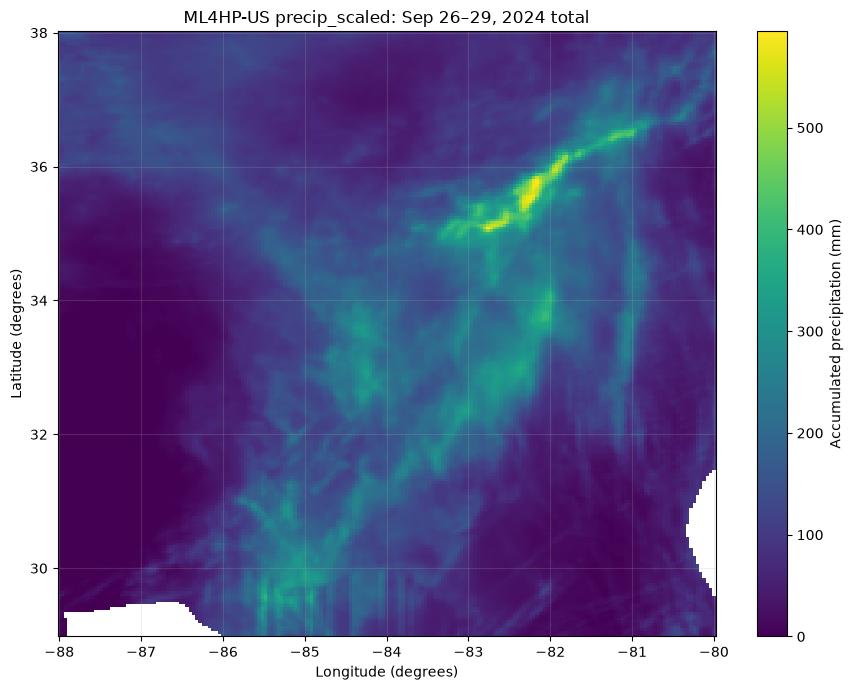

Maximum grid-cell storm total (mm): 594.6710205078125


In [6]:
import pandas as pd

expected_times = pd.date_range(START, END, freq='h')
actual_times = pd.DatetimeIndex(rain.time.values)
missing_times = expected_times.difference(actual_times)
print('Expected hours:', len(expected_times), '| Available:', len(actual_times))
print('Missing hour-start timestamps:', len(missing_times))
if len(missing_times):
    print('First missing timestamps:', list(missing_times[:10]))
if actual_times.has_duplicates:
    raise ValueError('Duplicate timestamps detected; resolve before aggregating.')

valid_hours = rain.count(dim='time')
total_mm = rain.sum(dim='time', min_count=1).where(valid_hours == len(expected_times))
total_mm.name = 'storm_total_precipitation'
total_mm.attrs.update(units='mm', long_name='Total over complete September 26-29, 2024 hourly intervals')
if len(missing_times):
    total_mm = total_mm * np.nan  # never report a complete-window total if timestamps are absent

storm_total = total_mm.load()
fig, ax = plt.subplots(figsize=(9, 7))
mesh = ax.pcolormesh(storm_total.lon, storm_total.lat, storm_total,
                     shading='auto', cmap='viridis', vmin=0)
fig.colorbar(mesh, ax=ax, label='Accumulated precipitation (mm)')
ax.set(xlabel='Longitude (degrees)', ylabel='Latitude (degrees)',
       title=f'ML4HP-US {VARIABLE}: Sep 26–29, 2024 total')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'helene_storm_total.png', dpi=180)
plt.show()

if bool(storm_total.notnull().any().item()):
    print('Maximum grid-cell storm total (mm):', float(storm_total.max(skipna=True).item()))
else:
    print('No grid cells have a complete event record; check data completeness before interpreting totals.')

## 8. Save a small, reusable event subset

This optional step creates a regional NetCDF suitable for sharing, testing, or future tutorials. The file contains both precipitation variables (if present) and only the selected event period/region. **Check the resulting file size before attempting to upload it.**

In [7]:
subset_vars = [v for v in ('precip_scaled', 'precip_raw') if v in ds]
small = ds[subset_vars].sel(
    time=slice(START, END),
    lat=ordered_slice(ds['lat'], LAT_MIN, LAT_MAX),
    lon=ordered_slice(ds['lon'], lon_low, lon_high)
)
small_file = OUTPUT_DIR / 'ml4hp_us_helene_20240926_20240929_subset.nc'
# Writing the small geographic subset is opt-in; uncomment the next lines when ready.
# small.to_netcdf(small_file, engine='netcdf4', encoding={
#     v: {'zlib': True, 'complevel': 4} for v in subset_vars
# })
# print(f'Saved {small_file} ({small_file.stat().st_size / 1e6:.1f} MB)')
print('Optional subset is ready. Uncomment the write command if you want to save it.')

Optional subset is ready. Uncomment the write command if you want to save it.


## 9. Access through AWS S3 (to complete after launch)

For now, this notebook accesses the local Delta archive. When AWS confirms the public S3 bucket and file layout, replace the local file path with the published S3 object URL or a staged download. **No S3 bucket or URL is invented here.**

A future public workflow may use `boto3`/AWS CLI with anonymous download if enabled, or `s3fs` plus an appropriate NetCDF access strategy. The exact method must be tested against the final published file layout and access policies.

- Project documentation: https://github.com/Hydroclimate-AI/ML4HP-US
- AWS Registry entry: **pending publication**
- Dataset license, DOI and citation: **pending final release/approval**

## 10. Community challenge

**How do hourly precipitation structure and storm-total rainfall differ across mountain and lowland regions during extreme tropical-cyclone events?**

Suggested investigations:

1. Compare the hourly intensity distribution and 4-day precipitation totals between the southern Appalachians and adjacent lowlands using ML4HP-US.
2. Investigate the sensitivity of event totals to the choice of time window and missing-data completeness threshold.
3. Where independent gauges or another verified product are available, evaluate the spatial pattern and timing of extreme precipitation rather than interpreting this single dataset as ground truth.
4. Extend the analysis to other landfalling tropical cyclones and test whether conclusions depend on local topography and storm tracks.

**Limitations:** This example does not model runoff or floods, attribute impacts solely to Helene, or claim observational validation. The release-stage quality assessment and published citation should be consulted when available.

---
**Next steps before AWS submission:** Execute against the real September 2024 file; inspect all figures and warnings; verify the period and region against your scientific use case; optionally add a locator map and an authoritative event reference; and update the access section after publication.